<a href="https://colab.research.google.com/github/michael-palomino-tm/Ingenier-a-de-Soluciones-con-Inteligencia-Artificial/blob/Mistral/RA3%20/IL3.1/3_1_4_Laboratorio_3_Evaluacion_Optimizacion_MercadoAndes_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ISY0101 · Ingeniería de Soluciones con IA
## EA3 · Actividad 1 — Laboratorio 3: Evaluación y optimización del agente MercadoAndes

**Contexto:** empresa ficticia MercadoAndes. Los datos y los escenarios de negocio son didácticos.

En el Laboratorio 1 registramos eventos y en el Laboratorio 2 examinamos trazas y *spans*. Ahora utilizaremos esa evidencia para **comparar dos implementaciones** y decidir si una modificación mejora el rendimiento del sistema.

**Al finalizar podrás:** definir KPIs, ejecutar pruebas comparables, detectar operaciones redundantes, analizar latencia y uso de recursos, y emitir una conclusión basada en resultados medidos.

> Este laboratorio no exige modificar la arquitectura del agente ni crear agentes adicionales. El objetivo es evaluar y mejorar una implementación existente.

## 1. Preparar Google Colab

En el panel **Secrets** de Google Colab, habilita el acceso a estas cuatro claves: `LLM_API_KEY`, `LLM_MODEL_SMALL`, `LLM_BASE_URL`, `LANGSMITH_API_KEY`.

La configuración se **lee exclusivamente desde Colab Secrets**: no se consultan archivos `.env` ni variables de entorno como origen de credenciales. La biblioteca LangSmith sí utiliza variables de entorno que configuraremos explícitamente a partir de esos secretos.

No imprimas ni copies los valores de las claves en resultados, capturas o repositorios.

In [1]:
# Instalamos solamente las dependencias que el laboratorio necesita agregar.
# Google Colab ya incluye Pandas y Matplotlib en versiones compatibles.
# Evitamos -U sobre esas bibliotecas para no romper dependencias de Colab.
%pip -q install langchain-openai langsmith


In [2]:
import os
import re
import time
import json
import uuid
import random
from email.utils import parsedate_to_datetime
from datetime import datetime, timezone

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata
from langchain_openai import ChatOpenAI
from langsmith import traceable


def obtener_secreto(nombre):
    """Lee un secreto de Colab y falla con un mensaje sin revelar su contenido."""
    try:
        valor = userdata.get(nombre)
    except Exception as exc:
        raise RuntimeError(f"No se pudo leer el secreto {nombre} de Colab.") from exc
    if not isinstance(valor, str) or not valor.strip():
        raise RuntimeError(f"El secreto {nombre} no está configurado o está vacío.")
    return valor.strip()

# Todas las fuentes de configuración son SECRETOS de Colab.
LLM_API_KEY = obtener_secreto("LLM_API_KEY")
LLM_MODEL_SMALL = obtener_secreto("LLM_MODEL_SMALL")
LLM_BASE_URL = obtener_secreto("LLM_BASE_URL")
LANGSMITH_API_KEY = obtener_secreto("LANGSMITH_API_KEY")

# Estas variables activan la instrumentación automática de LangSmith.
# No se leen desde el entorno: se asignan aquí con datos ya obtenidos desde Secrets.
os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "ISY0101-EA3-Observabilidad"

# Mistral ofrece una API compatible con el protocolo de ChatOpenAI.
llm = ChatOpenAI(
    model=LLM_MODEL_SMALL,
    api_key=LLM_API_KEY,
    base_url=LLM_BASE_URL,
    temperature=0,
    max_retries=0,  # Reintentos 429 controlados y registrados por nuestro código.
)

print("Configuración cargada correctamente desde Colab Secrets.")
print("Trazabilidad habilitada para el proyecto ISY0101-EA3-Observabilidad.")
# No mostramos el modelo ni el endpoint para mantener el criterio de secretos.

Configuración cargada correctamente desde Colab Secrets.
Trazabilidad habilitada para el proyecto ISY0101-EA3-Observabilidad.


## 2. Problema y diseño de la comparación

MercadoAndes presenta una reducción de pedidos y señales de congestión en sus despachos. La solución consulta dos fuentes locales: **comercial** y **operacional**.

Compararemos dos versiones:

- **Versión A (inicial):** ejecuta una consulta operacional **redundante** y repite una espera artificial asociada a esa consulta.
- **Versión B (optimizada):** consulta los datos operacionales una sola vez y reutiliza el resultado.

Ambas versiones envían al LLM exactamente los **mismos datos de negocio**. Así aislamos un cambio específico en el flujo y evitamos confundir una variación de contenido con una optimización de operaciones.

**Hipótesis de trabajo:** al eliminar la llamada redundante se reducirá la latencia y el número de invocaciones de herramientas, sin perder evidencia de negocio. Las llamadas externas al LLM seguirán teniendo variabilidad natural.

In [3]:
# Datos FIJOS y ficticios de MercadoAndes, compartidos por ambas versiones.
DATOS_COMERCIALES = {
    "pedidos_trimestre_anterior": 1200,
    "pedidos_trimestre_actual": 1020,
    "abandono_carritos_pct": 32,
    "reclamos_totales": 230,
    "reclamos_entrega_tardia": 138,
}
DATOS_OPERACIONES = {
    "despachos_requeridos_semana": 400,
    "capacidad_despachos_semana": 320,
    "entregas_tardias_pct": 27,
}

# Una espera determinística para simular una herramienta que consulta un servicio lento.
# No representa la latencia del LLM ni una medición de producción.
DEMORA_OPERACIONES_SEG = 0.6

# Preguntas de prueba: repetiremos las mismas en A y B.
CASOS = [
    {"id": "C1", "pregunta": "Resume la evolución de pedidos y el abandono de carritos."},
    {"id": "C2", "pregunta": "Describe el problema de capacidad semanal de despachos."},
    {"id": "C3", "pregunta": "Relaciona reclamos por entregas tardías y capacidad logística, sin afirmar causalidad."},
]

print("Casos de prueba:", len(CASOS))
print("Demora ficticia por consulta operacional:", DEMORA_OPERACIONES_SEG, "segundos")

Casos de prueba: 3
Demora ficticia por consulta operacional: 0.6 segundos


## 3. Instrumentación de herramientas

Usaremos `@traceable` para registrar individualmente las funciones que consultan datos. Los estudiantes podrán ver cada invocación como una operación hija en LangSmith.

Además contabilizaremos las invocaciones realizadas en cada solicitud. **Contar llamadas** permite detectar redundancias incluso si una herramienta responde tan rápido que su latencia resulta difícil de apreciar.

In [4]:
@traceable(run_type="tool", name="mercadoandes_consulta_comercial")
def consulta_comercial():
    """Devuelve una copia de los datos comerciales controlados."""
    return dict(DATOS_COMERCIALES)


@traceable(run_type="tool", name="mercadoandes_consulta_operaciones")
def consulta_operaciones():
    """Simula la latencia de consultar un servicio de operaciones."""
    time.sleep(DEMORA_OPERACIONES_SEG)
    return dict(DATOS_OPERACIONES)


def extraer_tokens(respuesta):
    """Recupera tokens reportados por el proveedor; no inventa valores faltantes."""
    # El cliente puede colocar el uso en usage_metadata o response_metadata.
    usage = getattr(respuesta, "usage_metadata", None) or {}
    metadata = getattr(respuesta, "response_metadata", None) or {}
    token_usage = metadata.get("token_usage", {}) or {}

    entrada = usage.get("input_tokens", token_usage.get("prompt_tokens"))
    salida = usage.get("output_tokens", token_usage.get("completion_tokens"))
    total = usage.get("total_tokens", token_usage.get("total_tokens"))
    return {"tokens_entrada": entrada, "tokens_salida": salida, "tokens_total": total}


def crear_prompt(pregunta, datos_comerciales, datos_operaciones):
    """Construye idéntico prompt de negocio para las versiones A y B."""
    evidencia = {
        "comercial": datos_comerciales,
        "operaciones": datos_operaciones,
    }
    return (
        "Eres un analista de MercadoAndes. Responde brevemente en español y con lenguaje profesional. "
        "Utiliza SOLO las cifras siguientes, sin inventar datos ni afirmar causalidad. "
        "Distingue observaciones de hipótesis. Incluye las cifras relevantes para la pregunta.\n\n"
        f"EVIDENCIA: {json.dumps(evidencia, ensure_ascii=False, sort_keys=True)}\n"
        f"PREGUNTA: {pregunta}"
    )

## 4. Dos versiones y política de reintentos

La **versión A** vuelve a consultar operaciones, aunque ya dispone de esos datos; la **versión B** reutiliza el resultado. Las dos entregan **idéntica evidencia** al LLM. Las llamadas de red no siempre responden: una respuesta **HTTP 429** significa que el proveedor ha limitado temporalmente el uso de su API. Esto no demuestra que el agente tenga una respuesta incorrecta.

Por eso añadiremos tres controles:

1. **Reintentos acotados** ante 429: respetamos `Retry-After` cuando sea posible, con una espera exponencial y un límite para no bloquear indefinidamente el laboratorio. Registramos cuántos intentos hubo y cuánto tiempo se esperó. No repetimos errores distintos de 429.
2. **Comparaciones equilibradas**: alternamos qué versión se ejecuta primero y rotamos el orden de los casos entre rondas.
3. **Separación de indicadores**: los fallos cuentan para disponibilidad; solo las ejecuciones exitosas cuentan para latencia de respuesta y tokens. Las comparaciones de tiempo A/B se hacen únicamente con pares donde **ambas** tuvieron éxito.

> Importante: la espera por un error 429 es un tiempo de recuperación, no tiempo de inferencia del modelo. El total de solicitud puede incluir esperas y reintentos; las registraremos por separado.


In [5]:
# Lista acumulativa de ejecuciones. Se restablece al comenzar cada experimento.
MEDICIONES = []

# Ajustes visibles para que cada estudiante pueda investigar el costo de esperar.
# Un solo reintento extra evita saturar el servicio en el laboratorio.
MAX_REINTENTOS_429 = 1        # 1 intento inicial + hasta 1 reintento
ESPERA_BASE_429_S = 20       # espera cuando el servidor no entrega Retry-After
ESPERA_MAXIMA_429_S = 60     # máximo por espera para que la práctica sea acotada


def identificar_429(exc):
    """Detecta un error HTTP 429 sin depender del nombre de la clase cliente."""
    status = getattr(exc, "status_code", None)
    respuesta = getattr(exc, "response", None)
    if status is None and respuesta is not None:
        status = getattr(respuesta, "status_code", None)
    return status == 429 or "RateLimitError" in type(exc).__name__


def obtener_retry_after(exc):
    """Lee Retry-After (segundos o fecha HTTP) sin exponer mensajes o credenciales."""
    respuesta = getattr(exc, "response", None)
    headers = getattr(respuesta, "headers", {}) or {}
    valor = headers.get("retry-after") or headers.get("Retry-After")
    if not valor:
        return None
    try:
        return max(0.0, float(valor))
    except (ValueError, TypeError):
        try:
            destino = parsedate_to_datetime(valor)
            return max(0.0, (destino - datetime.now(timezone.utc)).total_seconds())
        except (ValueError, TypeError, OverflowError):
            return None


def invocar_con_reintento(prompt, seguimiento):
    """Devuelve respuesta y métricas de intentos; solo reintenta ante rate limit.

    Los reintentos usan el mismo prompt, por lo que NO son una mejora del agente.
    Si se agota el presupuesto, propagamos el fallo al ejecutor para registrarlo.
    """
    inicio = time.perf_counter()
    espera_total = 0.0
    intentos = 0
    for reintento in range(MAX_REINTENTOS_429 + 1):
        intentos += 1
        seguimiento["intentos_llm"] = intentos
        try:
            respuesta = llm.invoke(prompt)
            seguimiento["latencia_llm_con_esperas_s"] = round(time.perf_counter() - inicio, 3)
            return respuesta
        except Exception as exc:
            if not identificar_429(exc) or reintento >= MAX_REINTENTOS_429:
                raise
            # Prioridad al encabezado del servidor. Si no hay, backoff exponencial.
            sugerida = obtener_retry_after(exc)
            if sugerida is None:
                sugerida = ESPERA_BASE_429_S * (2 ** reintento)
                sugerida += random.uniform(0, 2)  # jitter pequeño entre intentos
            espera = min(sugerida, ESPERA_MAXIMA_429_S)
            print(f"  API limitada (429). Reintento {reintento+1}/{MAX_REINTENTOS_429}; espera {espera:.1f} s")
            time.sleep(espera)
            espera_total += espera
            seguimiento["espera_reintentos_s"] = round(espera_total, 3)


@traceable(run_type="chain", name="MercadoAndes_Lab3_comparacion")
def ejecutar_version(version, caso, ronda=1):
    """Mide una solicitud y distingue los fallos de API de la calidad del contenido."""
    if version not in ("A", "B"):
        raise ValueError("La versión debe ser A o B.")

    run_id = str(uuid.uuid4())[:8]
    inicio_total = time.perf_counter()
    llamadas_herramienta = 0
    resultado = {
        "run_id": run_id, "ronda": ronda, "version": version,
        "caso": caso["id"], "pregunta": caso["pregunta"], "estado": "error",
        "latencia_total_s": None, "latencia_llm_s": None,
        "latencia_llm_con_esperas_s": None, "espera_reintentos_s": 0.0,
        "intentos_llm": 0, "llamadas_herramientas": None,
        "tokens_entrada": None, "tokens_salida": None, "tokens_total": None,
        "respuesta": None, "error_tipo": None, "error_categoria": None,
        "datos_integrados_correctos": False,
    }

    try:
        comercial = consulta_comercial()
        llamadas_herramienta += 1
        operaciones = consulta_operaciones()
        llamadas_herramienta += 1
        if version == "A":
            # Esta consulta extra NO se incluye en la evidencia enviada al modelo.
            _ = consulta_operaciones()
            llamadas_herramienta += 1

        prompt = crear_prompt(caso["pregunta"], comercial, operaciones)
        resultado["datos_integrados_correctos"] = (
            comercial == DATOS_COMERCIALES and operaciones == DATOS_OPERACIONES
        )
        inicio_llm = time.perf_counter()
        try:
            respuesta_llm = invocar_con_reintento(prompt, resultado)
        finally:
            # Duración total de la etapa LLM, incluidos posibles reintentos.
            resultado["latencia_llm_s"] = round(time.perf_counter() - inicio_llm, 3)
            resultado["latencia_llm_con_esperas_s"] = resultado["latencia_llm_s"]

        resultado["respuesta"] = str(respuesta_llm.content)
        resultado.update(extraer_tokens(respuesta_llm))
        resultado["estado"] = "ok"

    except Exception as exc:
        # Nunca guardamos el texto de la excepción: podría incluir secretos.
        resultado["error_tipo"] = type(exc).__name__
        resultado["error_categoria"] = "limite_api_429" if identificar_429(exc) else "otro_error"
        # No inferimos tokens de una respuesta que no existe.
    finally:
        resultado["latencia_total_s"] = round(time.perf_counter() - inicio_total, 3)
        resultado["llamadas_herramientas"] = llamadas_herramienta

    return resultado


## 5. Repetir pruebas sin mezclar resultados

Ejecutaremos un conjunto pequeño de pruebas con ambos enfoques. Una **ronda** incluye todos los casos y ambas versiones. Al iniciar una ronda nueva, el código **limpia los resultados anteriores** para que la tabla no mezcle experimentos.

El orden de los casos se rota entre rondas y el orden de las versiones se alterna; esto reduce un sesgo de posición, aunque **no elimina** las fluctuaciones de la API. Para investigar más, se pueden aumentar las rondas, considerando cuotas y tiempos de ejecución.

Si el proveedor devuelve HTTP 429, el notebook espera y reintenta **una sola vez** de forma controlada. Si vuelve a fallar, la fila se conserva como error. **Nunca se transforma automáticamente en un éxito simulado.**


In [6]:
# Se limpia el historial: evita mezclar esta prueba con ejecuciones anteriores.
MEDICIONES.clear()

# Una ronda implica seis solicitudes (3 preguntas x 2 versiones).
# Se puede aumentar, considerando la cuota disponible en Mistral.
RONDAS = 2
PAUSA_ENTRE_CASOS_S = 15  # pausa entre pares A/B, no necesaria dentro de cada par

for ronda in range(1, RONDAS + 1):
    # Rotamos el orden de los casos para que C2 no quede siempre al medio.
    desplazamiento = (ronda - 1) % len(CASOS)
    casos_ordenados = CASOS[desplazamiento:] + CASOS[:desplazamiento]

    for posicion, caso in enumerate(casos_ordenados):
        # Alternamos la primera versión para reducir el sesgo de orden.
        versiones = ("A", "B") if (posicion + ronda) % 2 == 1 else ("B", "A")
        for version in versiones:
            fila = ejecutar_version(version, caso, ronda=ronda)
            MEDICIONES.append(fila)
            print(
                f"R{ronda} | {fila['caso']} | {version} | {fila['estado']} | "
                f"{fila['latencia_total_s']:.2f} s | "
                f"{fila['llamadas_herramientas']} herramientas | "
                f"{fila['intentos_llm']} intento(s) LLM"
            )
        # Evitamos pausas innecesarias después del último caso.
        if posicion < len(casos_ordenados) - 1:
            time.sleep(PAUSA_ENTRE_CASOS_S)

# Se conserva una única tabla con los resultados de este experimento.
df = pd.DataFrame(MEDICIONES)
df["latencia_operativa_s"] = (
    df["latencia_total_s"] - df["espera_reintentos_s"]
)
columnas_vista = [
    "ronda", "caso", "version", "estado", "latencia_total_s",
    "latencia_llm_s", "latencia_operativa_s", "espera_reintentos_s", "intentos_llm",
    "llamadas_herramientas", "tokens_total", "error_categoria", "error_tipo"
]

display(df[columnas_vista])


R1 | C1 | A | ok | 4.76 s | 3 herramientas | 1 intento(s) LLM
R1 | C1 | B | ok | 3.01 s | 2 herramientas | 1 intento(s) LLM
  API limitada (429). Reintento 1/1; espera 20.1 s
R1 | C2 | B | ok | 24.42 s | 2 herramientas | 2 intento(s) LLM
R1 | C2 | A | ok | 3.39 s | 3 herramientas | 1 intento(s) LLM
  API limitada (429). Reintento 1/1; espera 22.0 s
R1 | C3 | A | error | 23.71 s | 3 herramientas | 2 intento(s) LLM
  API limitada (429). Reintento 1/1; espera 20.0 s
R1 | C3 | B | ok | 22.48 s | 2 herramientas | 2 intento(s) LLM
R2 | C2 | B | ok | 5.04 s | 2 herramientas | 1 intento(s) LLM
  API limitada (429). Reintento 1/1; espera 20.9 s
R2 | C2 | A | error | 22.59 s | 3 herramientas | 2 intento(s) LLM
R2 | C3 | A | ok | 4.03 s | 3 herramientas | 1 intento(s) LLM
R2 | C3 | B | ok | 3.54 s | 2 herramientas | 1 intento(s) LLM
  API limitada (429). Reintento 1/1; espera 20.3 s
R2 | C1 | B | error | 21.39 s | 2 herramientas | 2 intento(s) LLM
  API limitada (429). Reintento 1/1; espera 21.4 

,ronda,caso,version,estado,latencia_total_s,latencia_llm_s,latencia_operativa_s,espera_reintentos_s,intentos_llm,llamadas_herramientas,tokens_total,error_categoria,error_tipo
0,1,C1,A,ok,4.764,3.558,4.764,0.000,1,3,533.0,None,None
1,1,C1,B,ok,3.009,2.396,3.009,0.000,1,2,514.0,None,None
2,1,C2,B,ok,24.421,23.819,4.325,20.096,2,2,515.0,None,None
3,1,C2,A,ok,3.386,2.182,3.386,0.000,1,3,484.0,None,None
4,1,C3,A,error,23.708,22.505,1.715,21.993,2,3,NaN,limite_api_429,OpenAIRateLimitError
5,1,C3,B,ok,22.480,21.875,2.457,20.023,2,2,436.0,None,None
6,2,C2,B,ok,5.038,4.435,5.038,0.000,1,2,546.0,None,None
7,2,C2,A,error,22.587,21.384,1.673,20.914,2,3,NaN,limite_api_429,OpenAIRateLimitError
8,2,C3,A,ok,4.033,2.829,4.033,0.000,1,3,534.0,None,None
9,2,C3,B,ok,3.536,2.934,3.536,0.000,1,2,454.0,None,None


## 6. KPIs de rendimiento y disponibilidad

El laboratorio diferencia indicadores:

- **Disponibilidad (éxito técnico):** proporción de solicitudes que terminan correctamente, contando también los fallos 429.
- **Frecuencia de errores 429 y reintentos:** evidencia de restricciones externas o del volumen de solicitudes.
- **Latencia total y tokens de respuesta:** calculados **solo en solicitudes exitosas**. La latencia total incluye cualquier espera por reintentos; por eso la mostramos junto a la espera acumulada.
- **Comparación justa A/B:** para cada caso y ronda, se consideran pares en que **ambas versiones fueron exitosas**. De otro modo estaríamos comparando una respuesta completa con un error anticipado.

Un promedio no demuestra causalidad. La mejora comprobable es que B elimina una llamada redundante; para atribuir mejoras de tiempo necesitamos repetición y control del entorno.


In [7]:
# KPI 1: disponibilidad. Incluye éxitos y errores de todas las ejecuciones.
resumen = df.groupby("version").agg(
    solicitudes=("caso", "count"),
    completadas=("estado", lambda s: int((s == "ok").sum())),
    errores_429=("error_categoria", lambda s: int((s == "limite_api_429").sum())),
    llamadas_promedio=("llamadas_herramientas", "mean"),
    intentos_llm_promedio=("intentos_llm", "mean"),
    integridad_datos=("datos_integrados_correctos", "mean"),
).reset_index()
resumen["exito_tecnico_pct"] = (100 * resumen["completadas"] / resumen["solicitudes"]).round(1)
resumen["error_429_pct"] = (100 * resumen["errores_429"] / resumen["solicitudes"]).round(1)

# KPI 2: rendimiento solo sobre respuestas completas.
exitos = df[df["estado"] == "ok"].copy()
if not exitos.empty:
    rendimiento = exitos.groupby("version").agg(
        latencia_promedio_s=("latencia_total_s", "mean"),
        latencia_llm_promedio_s=("latencia_llm_s", "mean"),
        espera_retry_promedio_s=("espera_reintentos_s", "mean"),
        tokens_promedio=("tokens_total", "mean"),
    ).reset_index()
    resumen = resumen.merge(rendimiento, on="version", how="left")
else:
    for campo in ("latencia_promedio_s", "latencia_llm_promedio_s",
                  "espera_retry_promedio_s", "tokens_promedio"):
        resumen[campo] = float("nan")

display(resumen.round(3))

# KPI 3: formamos pares por ronda y caso; ambos lados deben tener estado 'ok'.
pares = df.pivot_table(
    index=["ronda", "caso"], columns="version",
    values=["latencia_total_s", "estado"], aggfunc="first"
)
comparaciones = []
for (ronda, caso), fila in pares.iterrows():
    estado_a = fila.get(("estado", "A"))
    estado_b = fila.get(("estado", "B"))
    if estado_a == "ok" and estado_b == "ok":
        tiempo_a = float(fila[("latencia_total_s", "A")])
        tiempo_b = float(fila[("latencia_total_s", "B")])
        comparaciones.append({
            "ronda": ronda, "caso": caso, "A_s": tiempo_a, "B_s": tiempo_b,
            "ahorro_B_s": round(tiempo_a - tiempo_b, 3)
        })
pares_validos = pd.DataFrame(comparaciones, columns=["ronda", "caso", "A_s", "B_s", "ahorro_B_s"])
print(f"Pares A/B con ambas respuestas exitosas: {len(pares_validos)} de {len(CASOS) * RONDAS}")
display(pares_validos)
if not pares_validos.empty:
    print("Ahorro promedio observado por par (s):", round(pares_validos["ahorro_B_s"].mean(), 3))


,version,solicitudes,completadas,errores_429,llamadas_promedio,intentos_llm_promedio,integridad_datos,exito_tecnico_pct,error_429_pct,latencia_promedio_s,latencia_llm_promedio_s,espera_retry_promedio_s,tokens_promedio
0,A,6,4,2,3.0,1.5,1.0,66.7,33.3,9.542,8.337,5.359,535.5
1,B,6,5,1,2.0,1.5,1.0,83.3,16.7,11.697,11.092,8.024,493.0


Pares A/B con ambas respuestas exitosas: 3 de 6


,ronda,caso,A_s,B_s,ahorro_B_s
0,1,C1,4.764,3.009,1.755
1,1,C2,3.386,24.421,-21.035
2,2,C3,4.033,3.536,0.497


Ahorro promedio observado por par (s): -6.261


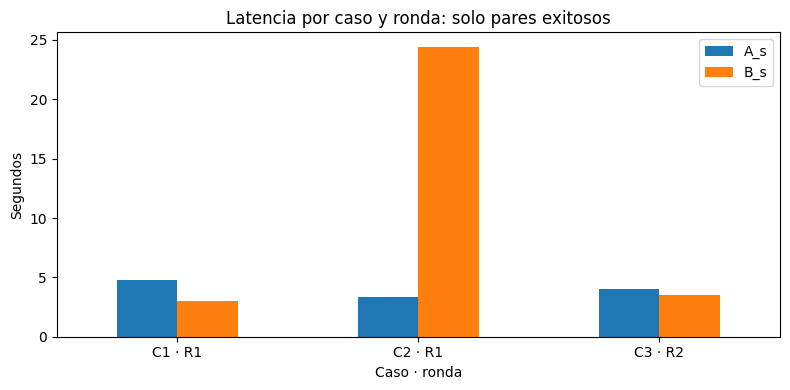

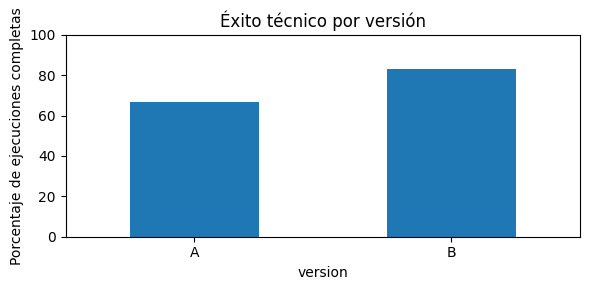

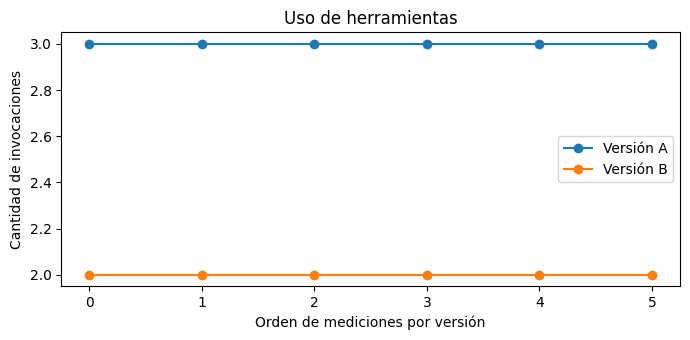

In [8]:
# Gráfico 1: comparar solo pares A/B que terminaron correctamente.
if not pares_validos.empty:
    grafico = pares_validos.copy()
    grafico["etiqueta"] = grafico["caso"] + " · R" + grafico["ronda"].astype(str)
    ax = grafico.set_index("etiqueta")[["A_s", "B_s"]].plot(
        kind="bar", figsize=(8, 4), rot=0
    )
    ax.set_title("Latencia por caso y ronda: solo pares exitosos")
    ax.set_xlabel("Caso · ronda")
    ax.set_ylabel("Segundos")
    plt.tight_layout()
    plt.show()
else:
    print("No hay pares A/B exitosos comparables. Revisar disponibilidad antes de comparar latencias.")

# Gráfico 2: disponibilidad (incluye 429); NO confundir con calidad del texto.
ax = resumen.set_index("version")["exito_tecnico_pct"].plot(kind="bar", figsize=(6, 3), rot=0)
ax.set_title("Éxito técnico por versión")
ax.set_ylabel("Porcentaje de ejecuciones completas")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

# Gráfico 3: número de llamadas del proceso, incluso si el modelo falló.
fig, ax = plt.subplots(figsize=(7, 3.5))
for version, subset in df.groupby("version"):
    ax.plot(range(len(subset)), subset["llamadas_herramientas"], marker="o", label=f"Versión {version}")
ax.set_xlabel("Orden de mediciones por versión")
ax.set_ylabel("Cantidad de invocaciones")
ax.set_title("Uso de herramientas")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Verificación de calidad de los resultados

La comparación de calidad se hace solo entre respuestas completas. Una modificación es útil si reduce trabajo innecesario **sin eliminar evidencia necesaria ni degradar la respuesta**.

El notebook comprueba automáticamente que ambas versiones integran los mismos registros de negocio. Eso no valida por sí solo la calidad del texto generado por Mistral: la exactitud, relevancia y prudencia de las conclusiones deben revisarse con una pauta explícita.

Para cada caso exitoso, revisa si la respuesta: (a) utiliza cifras pertinentes, (b) responde la pregunta y (c) evita presentar asociaciones como causas demostradas.

In [9]:
# Pauta de revisión MANUAL: cada estudiante puede contrastar respuestas A/B.
# No se asigna calidad = 100 % por el mero hecho de no haber excepciones.
revision = df[["caso", "version", "estado", "datos_integrados_correctos", "respuesta"]].copy()
revision["cifras_pertinentes"] = pd.NA  # Completar con Sí / No tras leer la respuesta.
revision["responde_la_pregunta"] = pd.NA
revision["evita_causalidad_injustificada"] = pd.NA

# Mostramos una respuesta a la vez para facilitar la revisión, sin modificar el dato.
for _, fila in revision.iterrows():
    print(f"\n--- Caso {fila['caso']} | versión {fila['version']} | {fila['estado']} ---")
    print((fila["respuesta"] or "Sin respuesta: ejecución fallida.")[:1200])

display(revision.drop(columns=["respuesta"]))


--- Caso C1 | versión A | ok ---
**Evolución de pedidos:**
- **Caída intertrimestral:** Los pedidos disminuyeron un **15%** (de **1.200** en el trimestre anterior a **1.020** en el actual).

**Abandono de carritos:**
- **Tasa de abandono:** **32%** (sin datos históricos para comparar tendencias).

---
**Observaciones:**
- La reducción en pedidos coincide con un **déficit de capacidad operativa** (requeridos: **400/semana** vs. capacidad: **320/semana**), lo que podría correlacionarse con limitaciones logísticas.
- El abandono de carritos (32%) es alto, pero no se dispone de datos previos para analizar su evolución.

**Hipótesis (sin causalidad afirmada):**
- La caída en pedidos podría estar vinculada a:
  1. **Falta de capacidad operativa** (brecha de **80 despachos/semana**).
  2. **Experiencia de entrega deteriorada** (27% de entregas tardías y **138 reclamos** por este motivo, representando el **60%** del total de reclamos).
- El abandono de carritos (32%) podría agravarse si los u

,caso,version,estado,datos_integrados_correctos,cifras_pertinentes,responde_la_pregunta,evita_causalidad_injustificada
0,C1,A,ok,True,<NA>,<NA>,<NA>
1,C1,B,ok,True,<NA>,<NA>,<NA>
2,C2,B,ok,True,<NA>,<NA>,<NA>
3,C2,A,ok,True,<NA>,<NA>,<NA>
4,C3,A,error,True,<NA>,<NA>,<NA>
5,C3,B,ok,True,<NA>,<NA>,<NA>
6,C2,B,ok,True,<NA>,<NA>,<NA>
7,C2,A,error,True,<NA>,<NA>,<NA>
8,C3,A,ok,True,<NA>,<NA>,<NA>
9,C3,B,ok,True,<NA>,<NA>,<NA>


## 8. Evidencia en LangSmith

Accede a [LangSmith](https://smith.langchain.com/) y abre el proyecto `ISY0101-EA3-Observabilidad`.

1. Busca las operaciones `MercadoAndes_Lab3_comparacion`.
2. Abre una ejecución de la versión A y observa sus llamadas a `mercadoandes_consulta_operaciones`.
3. Contrástala con una ejecución B del mismo caso.
4. Revisa los tiempos y la llamada al modelo. ¿Cuál es la parte que cambió realmente?
5. Si una prueba falló, identifica la operación y verifica qué métricas quedaron sin información.

Los tiempos de la API no son completamente reproducibles: el propósito es **identificar operaciones concretas** y respaldar las conclusiones con medidas, no obtener siempre los mismos números.

## 9. Guardar mediciones

Exportaremos el experimento actual a CSV. Los campos diferencian **ronda, estado técnico, reintentos, espera causada por la API y tiempos observados**. No incluiremos los prompts ni las respuestas completas en el archivo exportado.


In [10]:
# Guardamos solo métricas: nunca claves, prompts ni respuestas libres.
columnas_exportacion = [
    "run_id", "ronda", "version", "caso", "estado",
    "latencia_total_s", "latencia_llm_s", "latencia_llm_con_esperas_s",
    "espera_reintentos_s", "intentos_llm", "llamadas_herramientas",
    "tokens_entrada", "tokens_salida", "tokens_total",
    "datos_integrados_correctos", "error_categoria", "error_tipo"
]
ruta_csv = "mercadoandes_lab3_comparacion_v2.csv"
df[columnas_exportacion].to_csv(ruta_csv, index=False)
print("Métricas guardadas en:", ruta_csv)


Métricas guardadas en: mercadoandes_lab3_comparacion_v2.csv


## 10. Preguntas de análisis

Responde usando tus resultados y las trazas de LangSmith. Distingue **mediciones**, **interpretaciones** y **limitaciones**.

1. ¿Cuántas veces consulta operaciones la versión A? ¿Y la B? ¿Por qué se considera redundante la consulta adicional?
2. ¿Qué diferencia de tiempo observas en los **pares válidos** A/B? ¿Se parece al costo fijo de la herramienta o queda afectada por el LLM?
3. ¿Cuántos errores HTTP 429 se registraron? ¿Qué pasó con los reintentos y las esperas? ¿Es correcto incluir una ejecución fallida en el promedio de latencia de respuesta?
4. ¿Por qué alternamos el orden A/B y rotamos los casos entre rondas? ¿Qué limitaciones persisten?
5. ¿Cuál es la diferencia entre éxito técnico, integridad de datos y calidad de respuesta? ¿Qué medición adicional necesitarías?
6. ¿Qué información reporta Mistral sobre tokens? ¿Qué valores debemos declarar como no disponibles cuando falla una llamada?
7. En LangSmith, ¿qué spans evidencian la mejora estructural? Redacta una conclusión profesional con formato **Hallazgo → Evidencia → Cambio → Resultado → Limitación**.


## 11. Cierre

La observabilidad permite demostrar una mejora de ingeniería mediante datos y trazas. La versión B elimina una llamada redundante, lo que constituye una **mejora estructural verificable**. La diferencia de tiempo entre ejecuciones, en cambio, puede verse afectada por la red, la variabilidad del LLM y límites de API.

En este laboratorio hemos aprendido a:

- Registrar reintentos y errores de disponibilidad sin presentar fallos como éxitos.
- Separar latencia de respuestas completas de errores anticipados.
- Evitar comparar resultados acumulados de distintas pruebas.
- Comparar versiones únicamente cuando ambos resultados son válidos.
- Documentar conclusiones con evidencia, límites y posibles factores de confusión.
